# PumpRadar -- Early Warning Model for Crypto Pump-and-Dump Events

## What problem are we solving?

A **pump-and-dump** is when a group of people secretly agree (often over
Telegram or Discord) to buy a lot of one low-liquidity coin at the same time.
The price jumps ("the pump"), other traders notice and buy in too, and then
the organizers sell everything into that demand ("the dump"), leaving late
buyers holding a coin that crashes back down.

This notebook trains and evaluates models that try to answer: **can we tell,
a few minutes before it happens, that a pump is about to start?**

## Why is this harder than a normal classification problem?

A naive way to test a model is to shuffle all your data randomly and put 70%
in training, 30% in testing. For pump events, this is a trap: rows from the
*same* pump event end up on *both* sides of the split, so the model can
partly "memorize" an event instead of learning something that generalizes to
events it has never seen. This notebook builds that honest split itself, and
then **measures exactly how much the shortcut (naive) split overstates
performance** -- that comparison is the main point of this notebook, not just
a side detail.

## How to read this notebook

- Every code cell has a short comment above the interesting lines explaining
  what that line does, written for someone who has not seen this codebase
  before.
- Every results table or chart is followed by one short "**Takeaway:**"
  paragraph in plain language.
- All numbers come from running real code in `src/pumpradar/` against the
  real labeled dataset -- nothing here is simulated or filled in by hand.


In [1]:
# Standard imports: json/Path for loading saved results, pandas for tables,
# matplotlib for charts. We also add the project's `src/` folder to the
# Python path so we can import our own `pumpradar` package.
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from pumpradar import exp_a, splits  # our own training/evaluation code

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

# A consistent color palette used in every chart below, so the notebook
# reads as one connected story instead of six different plotting styles.
PALETTE = {
    "honest": "#4C72B0",   # blue  -- the trustworthy, leakage-safe split
    "random": "#DD8452",   # orange -- the naive split, shown for contrast
    "accent": "#55A868",   # green -- used for single-series highlight charts
}

print(f"project root: {PROJECT_ROOT}")


project root: C:\Users\sande\Pump-Radar


## 1. The dataset

We use a real, publicly documented dataset of labeled pump events: for 327
historical pumps, every coin's trading activity is recorded second-by-second
(aggregated into 25-second chunks) in the hours around the event, with a
`gt` (ground truth) flag marking the exact chunk where the pump was
confirmed to have started.

The cell below loads that raw file and reports its real size -- nothing is
downsampled or filled in for this notebook.


In [2]:
# Load the raw labeled feature file (one row per 25-second chunk per coin).
raw = exp_a.load_raw_features()

print(f"rows: {len(raw):,}")
print(f"distinct pump events: {raw['pump_index'].nunique()}")
print(f"distinct coins: {raw['symbol'].nunique()}")
print(f"date range: {raw['date'].min()} .. {raw['date'].max()}")
print(f"rows flagged as a confirmed pump moment (gt==1): {int((raw['gt'] == 1).sum())} "
      f"({(raw['gt'] == 1).mean():.3%} of all rows)")
raw.head()


rows: 482,157
distinct pump events: 327
distinct coins: 85
date range: 2018-01-02 18:14:35 .. 2021-01-19 16:58:20
rows flagged as a confirmed pump moment (gt==1): 317 (0.066% of all rows)


,date,pump_index,std_rush_order,avg_rush_order,std_trades,std_volume,avg_volume,std_price,avg_price,avg_price_max,hour_sin,hour_cos,minute_sin,minute_cos,symbol,gt
0,2018-12-29 17:00:25,0,-0.001,-0.005,0.0,0.000,-0.000,-0.0,-0.001,-0.001,-0.998,-0.068,0.000,1.000,BRD,0
1,2018-12-29 17:01:40,0,0.000,0.000,0.0,0.000,-0.000,-0.0,-0.001,-0.001,-0.998,-0.068,0.106,0.994,BRD,0
2,2018-12-29 17:02:05,0,0.000,0.000,0.0,-0.000,-0.002,-0.0,-0.001,-0.001,-0.998,-0.068,0.211,0.977,BRD,0
3,2018-12-29 17:25:00,0,0.000,0.000,0.0,-0.001,-0.004,-0.0,0.000,0.000,-0.998,-0.068,0.461,-0.887,BRD,0
4,2018-12-29 17:35:50,0,0.000,0.000,-0.0,-0.000,0.000,-0.0,0.000,0.000,-0.998,-0.068,-0.553,-0.833,BRD,0


## 2. Exploring the data (EDA)

Before training anything, it helps to look at the data directly: which coins
get pumped most often, how different a "pump moment" row looks from an
ordinary row, and whether our engineered features are redundant with each
other.


### 2.1 Which coins show up most often?

Pump-and-dump groups tend to target the same kind of low-liquidity coins
repeatedly. The chart below counts how many of the 327 labeled events belong
to each coin, for the 15 most frequently targeted coins.


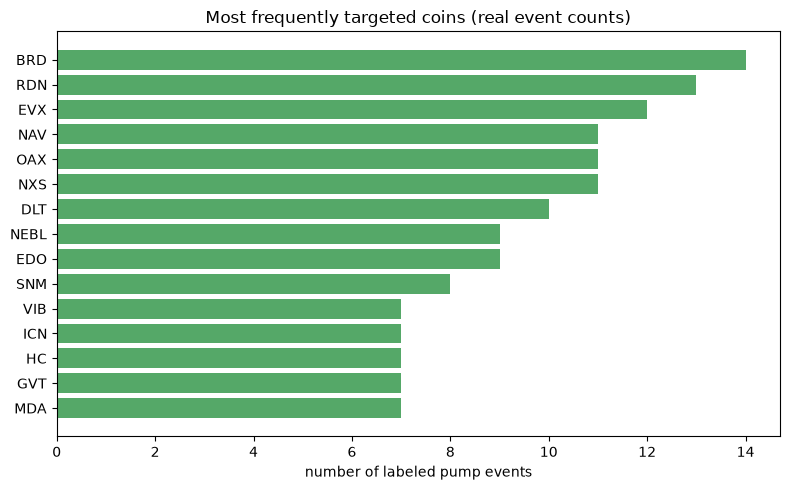

In [3]:
# Count how many distinct pump events each coin appears in, and keep the
# top 15 most frequently targeted coins.
events_per_coin = raw.groupby("symbol")["pump_index"].nunique().sort_values(ascending=False)
top15 = events_per_coin.head(15)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top15.index[::-1], top15.values[::-1], color=PALETTE["accent"])
ax.set_xlabel("number of labeled pump events")
ax.set_title("Most frequently targeted coins (real event counts)")
plt.tight_layout()
plt.show()


**Takeaway:** a small number of coins account for a disproportionate share
of events. That is exactly why the evaluation split matters so much: if the
same few coins/events appear in both train and test, a model can learn
"coin X tends to pump" rather than a real, transferable early-warning
signal (we test this directly in Section 6, the coin-identity check).


### 2.2 What does a "pump moment" row actually look like?

Each row has engineered trading-activity features (order-book "rush"
intensity, trade count, volume, price), already expressed as z-scores
relative to that coin's own recent history (so a value of 0 is "normal for
this coin", not zero volume). The chart below compares the **average** value
of each feature for confirmed pump-moment rows (`gt == 1`) against ordinary
rows (`gt == 0`).


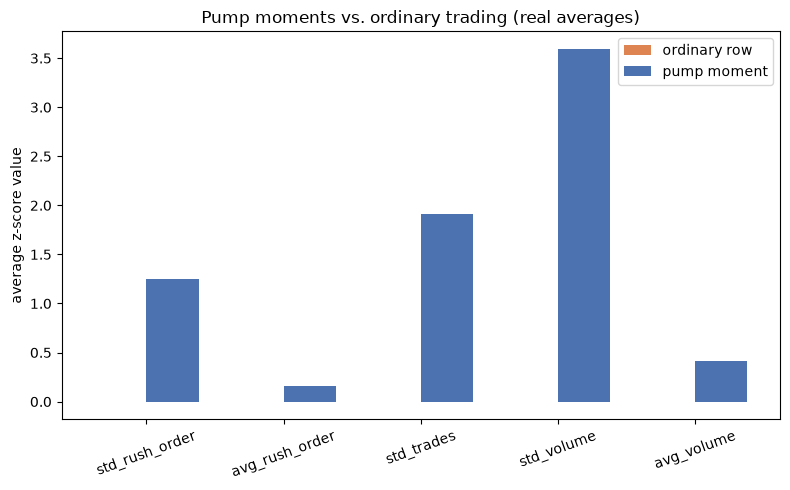

,ordinary row (gt=0),pump moment (gt=1)
std_rush_order,-0.0004,1.2523
avg_rush_order,-0.0002,0.1558
std_trades,-0.0003,1.9153
std_volume,-0.0003,3.5939
avg_volume,-0.0002,0.4127


In [4]:
# Average each feature separately for pump-moment rows vs. ordinary rows.
feature_cols = ["std_rush_order", "avg_rush_order", "std_trades", "std_volume", "avg_volume"]
by_label = raw.groupby("gt")[feature_cols].mean().T
by_label.columns = ["ordinary row (gt=0)", "pump moment (gt=1)"]

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(feature_cols))
width = 0.38
ax.bar(x - width / 2, by_label["ordinary row (gt=0)"], width, label="ordinary row", color=PALETTE["random"])
ax.bar(x + width / 2, by_label["pump moment (gt=1)"], width, label="pump moment", color=PALETTE["honest"])
ax.set_xticks(x)
ax.set_xticklabels(feature_cols, rotation=20)
ax.set_ylabel("average z-score value")
ax.set_title("Pump moments vs. ordinary trading (real averages)")
ax.legend()
plt.tight_layout()
plt.show()

by_label.round(4)


**Takeaway:** every feature is dramatically higher, on average, right at a
pump moment -- `std_rush_order` alone jumps from essentially 0 to over 1.2.
This confirms the labeled pump moments are real, detectable spikes in
trading activity, not noise -- which is what makes early warning plausible
in principle.


### 2.3 Are these features redundant with each other?

If two features are almost perfectly correlated, a model gains little by
having both. The heatmap below shows the correlation between every pair of
engineered features across all rows.


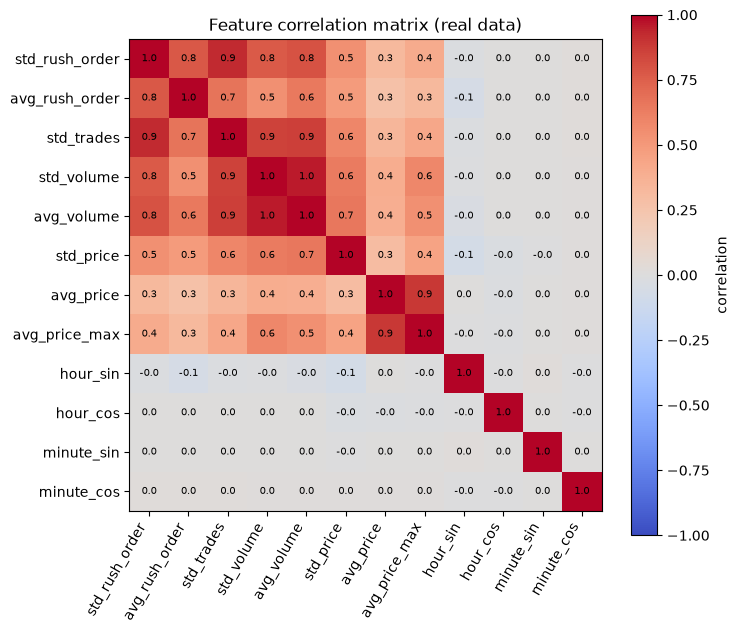

In [5]:
# Compute a correlation matrix across all engineered features, then draw it
# as a heatmap (dark/light color = strong positive/negative correlation).
all_feature_cols = feature_cols + ["std_price", "avg_price", "avg_price_max",
                                    "hour_sin", "hour_cos", "minute_sin", "minute_cos"]
corr = raw[all_feature_cols].corr()

fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(all_feature_cols)))
ax.set_xticklabels(all_feature_cols, rotation=60, ha="right")
ax.set_yticks(range(len(all_feature_cols)))
ax.set_yticklabels(all_feature_cols)
for i in range(len(all_feature_cols)):
    for j in range(len(all_feature_cols)):
        ax.text(j, i, f"{corr.values[i, j]:.1f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, label="correlation")
ax.set_title("Feature correlation matrix (real data)")
plt.tight_layout()
plt.show()


**Takeaway:** the volume/trade/order features (left block) are only loosely
correlated with each other and almost uncorrelated with the time-of-day
encodings (`hour_sin/cos`, `minute_sin/cos`) -- so there is no redundancy to
remove there. We will come back to the time-of-day columns in Section 8:
they turn out to matter a lot more than expected.


## 3. Turning raw rows into a labeled early-warning dataset

For every event, we find its **onset** (the first confirmed pump-moment
row) and compute every other row's **lead time**: how many minutes before
that onset it occurred. We only keep rows strictly before onset, within a
6-hour (360-minute) lookback window, and we build one yes/no label per
early-warning horizon we care about (1, 3, 5, 10, 30, 60 minutes): "is a
pump going to start within the next `h` minutes?"

Events with no confirmed onset row at all (10 of the 327) are dropped, since
there is nothing to count down to.


In [6]:
# Build the labeled early-warning dataset: adds `lead_min` (minutes to
# onset) and one binary label column per horizon (y_1, y_3, ..., y_60).
prepared = exp_a.prepare_experiment_a_dataset(raw)
summary = exp_a.summarize(prepared)

print(f"rows after preprocessing: {summary['n_rows']:,}")
print(f"events used: {summary['n_pump_groups_used']} / {summary['n_pump_groups_total']} "
      f"({summary['n_pump_groups_without_onset_excluded']} dropped -- no confirmed onset row)")
print(f"symbols: {summary['n_symbols']}")
print()
print("positives per horizon (count, prevalence):")
for h in exp_a.HORIZONS_MIN:
    n_pos = summary["positives_per_horizon"][f"y_{h}"]
    print(f"  h={h:>2} min: {n_pos:>6,} positives  ({n_pos / summary['n_rows']:.3%} of rows)")


rows after preprocessing: 55,141
events used: 317 / 327 (10 dropped -- no confirmed onset row)
symbols: 85

positives per horizon (count, prevalence):
  h= 1 min:    320 positives  (0.580% of rows)
  h= 3 min:    959 positives  (1.739% of rows)
  h= 5 min:  1,536 positives  (2.786% of rows)
  h=10 min:  2,836 positives  (5.143% of rows)
  h=30 min:  7,171 positives  (13.005% of rows)
  h=60 min: 12,822 positives  (23.253% of rows)


### 3.1 How far ahead of onset does our data actually reach?

The histogram below shows every row's lead time (minutes before onset). A
flat-ish distribution means we have reasonably dense data across the whole
6-hour window, not just right before onset.


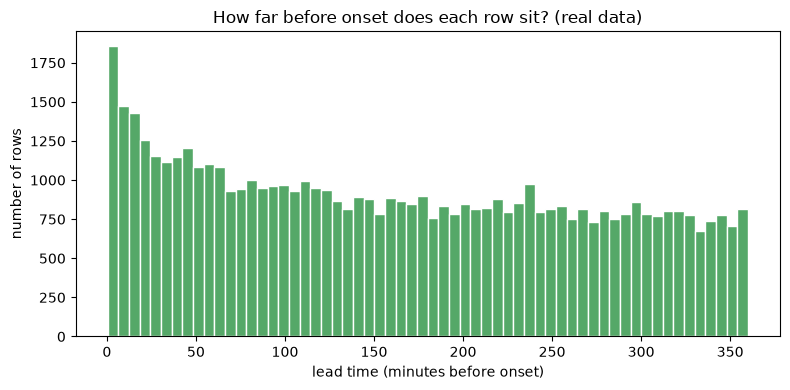

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(prepared["lead_min"], bins=60, color=PALETTE["accent"], edgecolor="white")
ax.set_xlabel("lead time (minutes before onset)")
ax.set_ylabel("number of rows")
ax.set_title("How far before onset does each row sit? (real data)")
plt.tight_layout()
plt.show()


**Takeaway:** rows are reasonably well spread across the full 6-hour
window, with somewhat more density close to onset (shorter lead times) --
consistent with chunk-level data being recorded continuously rather than
only sampled right before the event.


### 3.2 Class balance per horizon

A short horizon (e.g. "will a pump start in the next 1 minute?") is rare by
definition -- most rows are far from any pump. A long horizon ("...in the
next 60 minutes?") is much more common, simply because the positive window
is wider. This matters because **average precision (AP)**, our main metric,
is sensitive to how rare the positive class is -- so AP values across
different horizons are not directly comparable without also looking at this
chart.


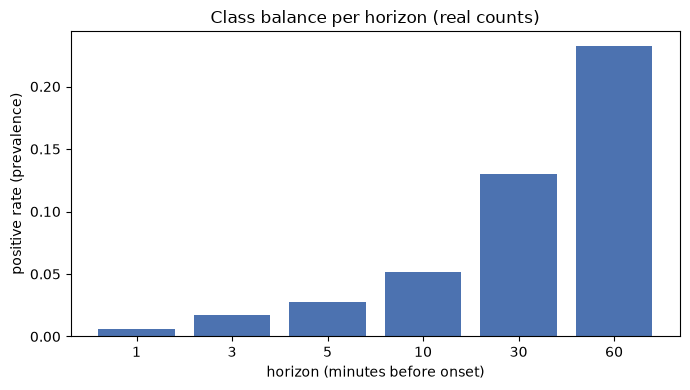

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
horizons = list(exp_a.HORIZONS_MIN)
prevalence = [summary["positives_per_horizon"][f"y_{h}"] / summary["n_rows"] for h in horizons]
ax.bar([str(h) for h in horizons], prevalence, color=PALETTE["honest"])
ax.set_xlabel("horizon (minutes before onset)")
ax.set_ylabel("positive rate (prevalence)")
ax.set_title("Class balance per horizon (real counts)")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results" / "figures" / "prevalence_by_horizon.png", dpi=120)
plt.show()


**Takeaway:** prevalence rises from 0.6% at 1 minute to 26% at 60 minutes.
This is expected (a wider window catches more positives), not a sign models
get "better" at longer horizons -- keep this chart in mind whenever
comparing AP across horizons later on.


## 4. Why the train/test split matters

We compare two ways of splitting data into train/test:

- **Honest split**: every event's rows stay together on one side, events
  are ordered by date (earliest 70% train, latest 30% test), and we remove
  ("embargo") any training row within 24 hours of the test period's start.
  This is how the model is actually evaluated everywhere else in this
  notebook.
- **Naive split**: rows are shuffled completely at random into 70%/30%. This
  is shown **only** as a point of comparison -- it is never used to report a
  real result.

The cell below proves, with real data, exactly why the naive split is
risky: it lets the same event's rows end up on both sides.


In [9]:
# Build both splits on the real labeled data.
honest_train_idx, honest_test_idx = splits.split_honest(
    prepared, key="pump_index", date_col="date", train_frac=0.7, purge="24h"
)
random_train_idx, random_test_idx = splits.split_random(prepared, seed=42, frac=0.7)

# This check raises an error if any event leaks across the honest split.
splits.assert_no_group_leak(prepared, "pump_index", honest_train_idx, honest_test_idx)
print("Honest split verified: no single event appears in both train and test.")

train, test = prepared.loc[honest_train_idx], prepared.loc[honest_test_idx]
print(f"  train: {len(train):,} rows, {train['pump_index'].nunique()} events, "
      f"{train['date'].min()} .. {train['date'].max()}")
print(f"  test:  {len(test):,} rows, {test['pump_index'].nunique()} events, "
      f"{test['date'].min()} .. {test['date'].max()}")

# For contrast: how many events leak across the naive random split?
r_train, r_test = prepared.loc[random_train_idx], prepared.loc[random_test_idx]
shared_events = set(r_train["pump_index"]) & set(r_test["pump_index"])
print()
print(f"Naive random split, for contrast: {len(shared_events)} of "
      f"{prepared['pump_index'].nunique()} events appear on BOTH sides. "
      "That is exactly the failure mode the honest split exists to prevent.")


Honest split verified: no single event appears in both train and test.
  train: 39,361 rows, 220 events, 2018-01-03 12:00:00 .. 2020-03-21 16:39:35
  test:  15,744 rows, 96 events, 2020-03-24 10:00:50 .. 2021-01-18 16:56:40

Naive random split, for contrast: 317 of 317 events appear on BOTH sides. That is exactly the failure mode the honest split exists to prevent.


## 5. Model tuning

We compare six general-purpose classifiers: Logistic Regression, K-Nearest
Neighbors, Decision Tree, Random Forest, Linear SVM, and LightGBM (gradient
boosted trees). Each model's hyperparameters were tuned **once**, using a
held-out validation slice (never the real test set), at the 10-minute
horizon, then reused unchanged across every horizon reported below.


In [10]:
with open(PROJECT_ROOT / "results" / "tuning_h10.json") as f:
    tuning = json.load(f)

for feature_set in ("clean", "full"):
    t = tuning[feature_set]
    print(f"-- {feature_set} feature set "
          f"(tuned on {t['n_train_events']} train / {t['n_val_events']} validation events) --")
    for model, params in t["chosen"].items():
        print(f"  {model:14s}: {params}")
    print()


-- clean feature set (tuned on 176 train / 44 validation events) --
  logreg        : {'C': 10.0}
  knn           : {'n_neighbors': 15}
  decision_tree : {'max_depth': 6}
  random_forest : {'max_depth': 6}
  linear_svm    : {'C': 1.0}
  lightgbm      : {'num_leaves': 15, 'max_depth': 8}

-- full feature set (tuned on 176 train / 44 validation events) --
  logreg        : {'C': 1.0}
  knn           : {'n_neighbors': 15}
  decision_tree : {'max_depth': 6}
  random_forest : {'max_depth': 6}
  linear_svm    : {'C': 0.1}
  lightgbm      : {'num_leaves': 15, 'max_depth': 8}



## 6. Individual model performance: honest vs. naive split

Now the main comparison: for every model, we measure **average precision
(AP)** -- how well the model ranks true pump rows above ordinary rows --
under both the honest and the naive split, at a 10-minute horizon. We do
this for two feature sets:

- **clean**: only order-flow/volume/trade features.
- **full**: clean features plus price-level and time-of-day columns.

"Inflation" = AP(naive) - AP(honest). A positive number means the naive
split made the model look better than it honestly is.


In [11]:
with open(PROJECT_ROOT / "results" / "metrics_A_tuned.json") as f:
    tuned_results = json.load(f)
records = pd.DataFrame(tuned_results["records"])
records = records[records["model"].notna()].copy()

print("=== h=10, clean feature set ===")
pivot_clean = records[(records.horizon_min == 10) & (records.feature_set == "clean")] \
    .pivot(index="model", columns="protocol", values="ap")
pivot_clean["inflation (naive - honest)"] = pivot_clean["random_P0"] - pivot_clean["honest_P2"]
display(pivot_clean.round(4).sort_values("inflation (naive - honest)", ascending=False))

print()
print("=== h=10, full feature set ===")
pivot_full = records[(records.horizon_min == 10) & (records.feature_set == "full")] \
    .pivot(index="model", columns="protocol", values="ap")
pivot_full["inflation (naive - honest)"] = pivot_full["random_P0"] - pivot_full["honest_P2"]
display(pivot_full.round(4).sort_values("inflation (naive - honest)", ascending=False))


=== h=10, clean feature set ===


protocol,honest_P2,random_P0,inflation (naive - honest)
model,,,
lightgbm,0.1024,0.1171,0.0146
logreg,0.1075,0.1079,0.0004
decision_tree,0.1015,0.1016,0.0001
linear_svm,0.1072,0.1057,-0.0015
random_forest,0.1215,0.1190,-0.0024
knn,0.0988,0.0903,-0.0085



=== h=10, full feature set ===


protocol,honest_P2,random_P0,inflation (naive - honest)
model,,,
knn,0.4131,0.5035,0.0904
lightgbm,0.5435,0.6293,0.0858
logreg,0.3908,0.4035,0.0127
linear_svm,0.3985,0.4109,0.0124
decision_tree,0.4703,0.4770,0.0067
random_forest,0.5743,0.5657,-0.0086


### 6.1 The same numbers, as a chart

Seeing all six models side by side makes the pattern easier to spot than
reading two tables.


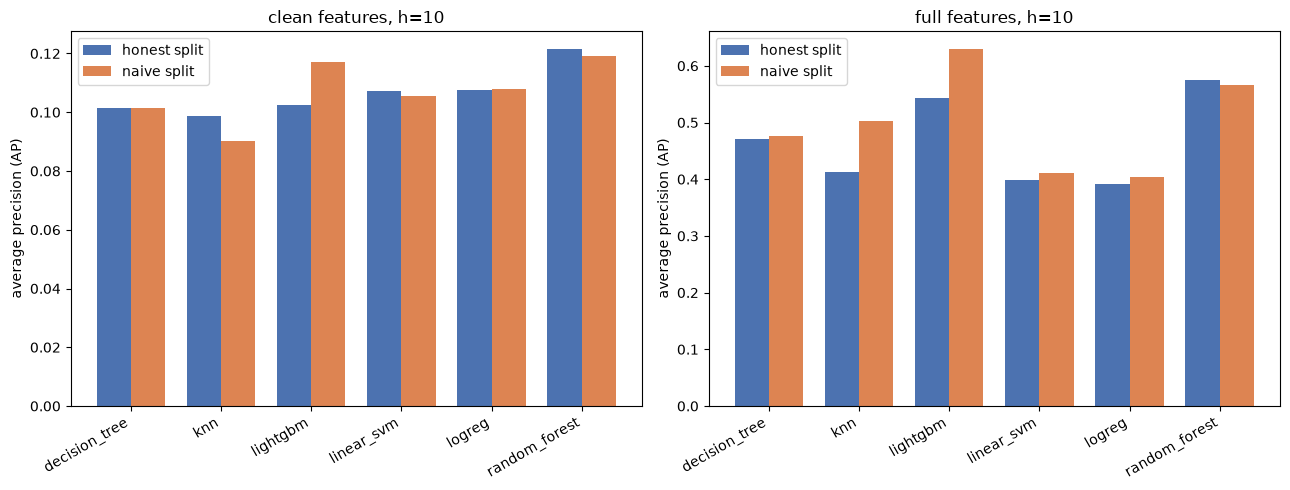

In [12]:
# Draw one bar-chart panel per feature set: each model gets two bars
# (honest split vs. naive split), so the inflation gap is visible directly.
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=False)
for ax, (feature_set, pivot) in zip(axes, [("clean", pivot_clean), ("full", pivot_full)]):
    models = pivot.index.tolist()
    x = np.arange(len(models))
    width = 0.38
    ax.bar(x - width / 2, pivot["honest_P2"], width, label="honest split", color=PALETTE["honest"])
    ax.bar(x + width / 2, pivot["random_P0"], width, label="naive split", color=PALETTE["random"])
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=30, ha="right")
    ax.set_ylabel("average precision (AP)")
    ax.set_title(f"{feature_set} features, h=10")
    ax.legend()
plt.tight_layout()
plt.show()


**Takeaway:** with clean features (left), the honest and naive bars are
almost the same height for every model -- little to no inflation. With full
features (right), the naive bar is visibly taller for most models, and the
gap is largest for the two highest-capacity models (KNN, LightGBM).


### 6.2 Cross-model comparison: precision-recall curves

AP is the area under a model's precision-recall curve. Plotting the actual
curves (from the real stored predictions, honest split, full features,
h=10) shows not just *who wins* but *how* -- e.g. a model that is much
better at high precision/low recall vs. one that is more consistent
throughout.


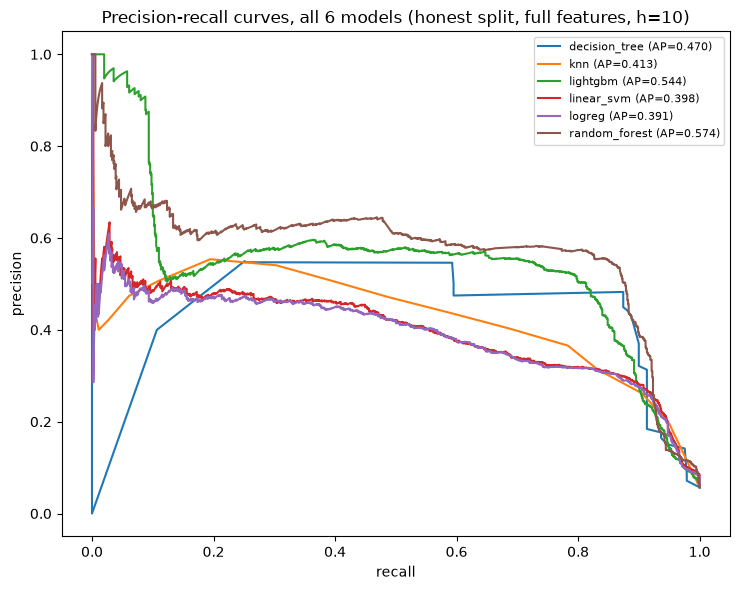

In [13]:
# Load the real per-row predictions saved during evaluation and compute an
# actual precision-recall curve for every model (no synthetic data).
from sklearn.metrics import precision_recall_curve

preds = pd.read_parquet(PROJECT_ROOT / "results" / "predictions_A_tuned.parquet")
subset = preds[(preds.horizon_min == 10) & (preds.protocol == "honest_P2") & (preds.feature_set == "full")]

fig, ax = plt.subplots(figsize=(7.5, 6))
for model, grp in subset.groupby("model"):
    precision, recall, _ = precision_recall_curve(grp["y_true"], grp["score"])
    ap = pivot_full.loc[model, "honest_P2"]
    ax.plot(recall, precision, label=f"{model} (AP={ap:.3f})")
ax.set_xlabel("recall")
ax.set_ylabel("precision")
ax.set_title("Precision-recall curves, all 6 models (honest split, full features, h=10)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


**Takeaway:** Random Forest and LightGBM dominate across almost the entire
recall range, not just in their headline AP number -- confirming the
ranking from the bar chart above is not an artifact of how AP summarizes
the curve.


## 7. Does the inflation gap hold across every horizon?

The chart below averages inflation across all six models, separately for
each horizon and feature set.


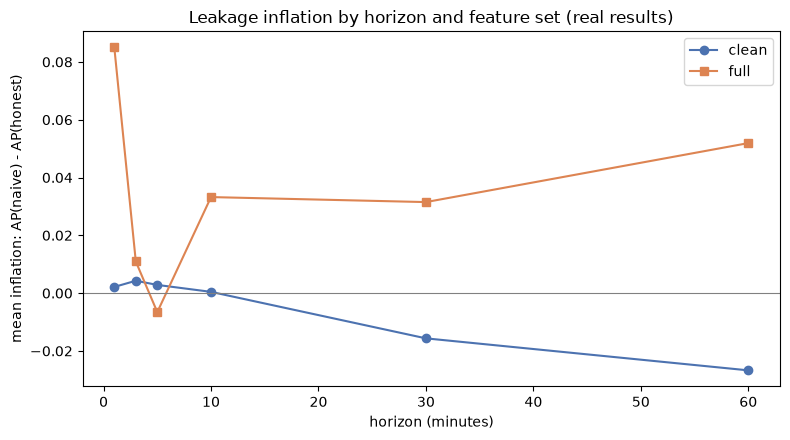

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for feature_set, marker, color in (("clean", "o", PALETTE["honest"]), ("full", "s", PALETTE["random"])):
    sub = records[records.feature_set == feature_set]
    mean_infl = (
        sub.pivot_table(index="horizon_min", columns="protocol", values="ap", aggfunc="mean")
        .assign(inflation=lambda d: d["random_P0"] - d["honest_P2"])
    )
    ax.plot(mean_infl.index, mean_infl["inflation"], marker=marker, label=feature_set, color=color)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel("horizon (minutes)")
ax.set_ylabel("mean inflation: AP(naive) - AP(honest)")
ax.set_title("Leakage inflation by horizon and feature set (real results)")
ax.legend()
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results" / "figures" / "inflation_by_horizon.png", dpi=120)
plt.show()


**Takeaway:** with clean features, inflation hovers near zero and flips sign
across horizons -- no consistent evidence of leakage-driven inflation. With
full features, inflation is consistently positive and largest for the
higher-capacity models -- a pattern consistent with memorization, though not
proof of it on its own (see Section 9's robustness checks).


## 8. Is the gap statistically real, or just noise?

We resample whole held-out **events** (never individual rows) 1,000 times
and recompute AP each time, giving a 95% confidence interval for each
model/feature-set/protocol combination at h=10.


In [15]:
with open(PROJECT_ROOT / "results" / "bootstrap_A_h10.json") as f:
    bootstrap = pd.DataFrame(json.load(f))

for feature_set in ("clean", "full"):
    print(f"-- {feature_set} --")
    sub = bootstrap[bootstrap.feature_set == feature_set].set_index(["model", "protocol"])
    display(sub[["ap_bootstrap_mean", "ci_low", "ci_high", "n_eligible_groups"]].round(4))
    print()


-- clean --


ap_bootstrap_mean  ci_low  ci_high  n_eligible_groups
model         protocol                                                        
decision_tree honest_P2             0.1035  0.0771   0.1364                 96
              random_P0             0.1022  0.0825   0.1246                317
knn           honest_P2             0.1005  0.0776   0.1273                 96
              random_P0             0.0911  0.0738   0.1112                317
lightgbm      honest_P2             0.1048  0.0773   0.1385                 96
              random_P0             0.1156  0.0939   0.1401                317
linear_svm    honest_P2             0.1102  0.0848   0.1407                 96
              random_P0             0.1073  0.0864   0.1330                317
logreg        honest_P2             0.1105  0.0849   0.1417                 96
              random_P0             0.1094  0.0879   0.1355                317
random_forest honest_P2             0.1173  0.0857   0.1571                 96
              random_P0             0.1161  0.0927   0.1429                317


-- full --


ap_bootstrap_mean  ci_low  ci_high  n_eligible_groups
model         protocol                                                        
decision_tree honest_P2             0.4751  0.3934   0.5688                 96
              random_P0             0.4789  0.4327   0.5280                317
knn           honest_P2             0.4167  0.3554   0.4936                 96
              random_P0             0.5053  0.4535   0.5549                317
lightgbm      honest_P2             0.5426  0.4759   0.6233                 96
              random_P0             0.6323  0.5805   0.6841                317
linear_svm    honest_P2             0.4036  0.3269   0.4985                 96
              random_P0             0.4135  0.3523   0.4754                317
logreg        honest_P2             0.3957  0.3204   0.4876                 96
              random_P0             0.4061  0.3445   0.4665                317
random_forest honest_P2             0.5651  0.4803   0.6629                 96
              random_P0             0.5947  0.5375   0.6549                317

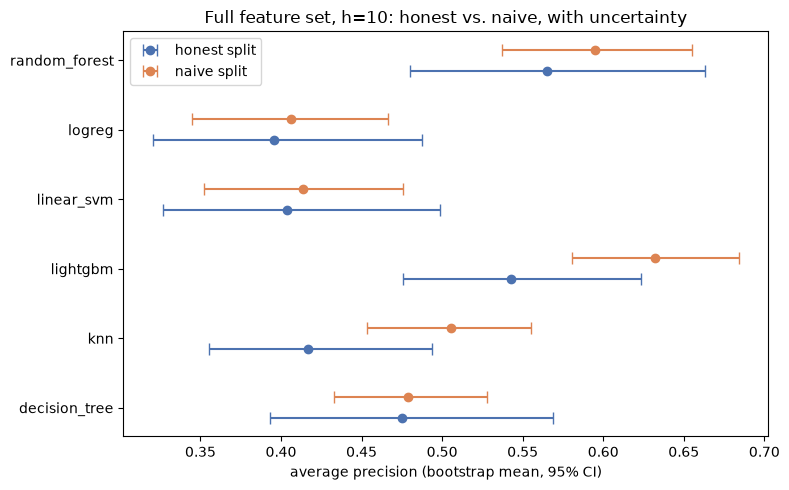

In [16]:
# Draw the honest-vs-naive confidence intervals side by side for the full
# feature set, so the overlap (or lack of it) is visible directly.
full_boot = bootstrap[bootstrap.feature_set == "full"]
models = sorted(full_boot["model"].unique())
fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(models))
for offset, protocol, color, label in ((-0.15, "honest_P2", PALETTE["honest"], "honest split"),
                                         (0.15, "random_P0", PALETTE["random"], "naive split")):
    sub = full_boot[full_boot.protocol == protocol].set_index("model").loc[models]
    err_low = sub["ap_bootstrap_mean"] - sub["ci_low"]
    err_high = sub["ci_high"] - sub["ap_bootstrap_mean"]
    ax.errorbar(sub["ap_bootstrap_mean"], y + offset, xerr=[err_low, err_high],
                fmt="o", color=color, label=label, capsize=4)
ax.set_yticks(y)
ax.set_yticklabels(models)
ax.set_xlabel("average precision (bootstrap mean, 95% CI)")
ax.set_title("Full feature set, h=10: honest vs. naive, with uncertainty")
ax.legend()
plt.tight_layout()
plt.show()


**Takeaway:** with only 96-220 held-out events to resample, no
model/feature-set combination clears a strict non-overlapping-95%-CI bar --
including the full-feature LightGBM and KNN cases with the largest
point-estimate inflation. Their intervals overlap, but only at the extreme
edges. This is a real, directionally consistent signal, not yet a
statistically decisive one at this sample size.


## 9. Diagnostic: is the model just memorizing which coin is which?

As a diagnostic only (never a real feature), we add a one-hot
coin-identity column to the clean feature set and see whether it helps
logistic regression under each split. If identity helps under the naive
split but not the honest one, that is a sign the naive split rewards coin
recognition rather than a real early-warning signal.


In [17]:
canary = tuned_results.get("canary_h10")
if canary is None:
    with open(PROJECT_ROOT / "results" / "metrics_A.json") as f:
        canary = json.load(f)["canary_h10"]

print(f"Naive split   AP without identity: {canary['random_P0_clean']:.4f}, "
      f"with identity: {canary['random_P0_clean_plus_identity']:.4f}, "
      f"lift: {canary['identity_lift_P0']:+.4f}")
print(f"Honest split  AP without identity: {canary['honest_P2_clean']:.4f}, "
      f"with identity: {canary['honest_P2_clean_plus_identity']:.4f}, "
      f"lift: {canary['identity_lift_P2']:+.4f}")


Naive split   AP without identity: 0.1079, with identity: 0.1163, lift: +0.0084
Honest split  AP without identity: 0.1076, with identity: 0.0854, lift: -0.0222


**Takeaway:** coin identity gives a small positive lift under the naive
split but a *negative* lift under the honest split -- exactly the pattern
you would expect if identity only helps when future events from the same
coin can leak into training. Under an honest evaluation, memorizing coin
identity actively hurts generalization.


## 10. Robustness checks: is this gap real, or an accident of one split?

Three follow-up checks, each changing one thing at a time:

1. **Split boundary** -- redo the honest split at five different
   train/test cutoffs (60% to 80% train).
2. **Random seed** -- redo the naive split with five different random
   seeds.
3. **Training-size isolation** -- hold the split *protocol* fixed and only
   change how much training data it gets, to rule out "more data" as the
   real explanation.


In [18]:
with open(PROJECT_ROOT / "results" / "sensitivity_checks.json") as f:
    sens = pd.DataFrame(json.load(f))

print("=== honest-split boundary sensitivity (LightGBM, h=10) ===")
display(sens[sens.check == "honest_boundary"][["train_frac", "feature_set", "ap", "n_train_events", "n_test_events"]])

print()
print("=== naive-split seed sensitivity (LightGBM, h=10) ===")
display(sens[sens.check == "random_seed"][["seed", "feature_set", "ap"]])

print()
print("=== naive-split training-size isolation (LightGBM, h=10) ===")
display(sens[sens.check == "P0_size_isolation"][["train_frac", "feature_set", "ap", "n_train_rows"]])


=== honest-split boundary sensitivity (LightGBM, h=10) ===


,train_frac,feature_set,ap,n_train_events,n_test_events
0,0.60,clean,0.108673,190.0,127.0
1,0.60,full,0.535880,190.0,127.0
2,0.65,clean,0.104897,206.0,111.0
3,0.65,full,0.514070,206.0,111.0
4,0.70,clean,0.102429,220.0,96.0
5,0.70,full,0.543503,220.0,96.0
6,0.75,clean,0.103134,237.0,80.0
7,0.75,full,0.555710,237.0,80.0
8,0.80,clean,0.097537,253.0,64.0
9,0.80,full,0.546476,253.0,64.0



=== naive-split seed sensitivity (LightGBM, h=10) ===


,seed,feature_set,ap
10,1.0,clean,0.112136
11,1.0,full,0.640354
12,2.0,clean,0.108683
13,2.0,full,0.629125
14,3.0,clean,0.104974
15,3.0,full,0.639444
16,4.0,clean,0.104934
17,4.0,full,0.638667
18,5.0,clean,0.099392
19,5.0,full,0.658664



=== naive-split training-size isolation (LightGBM, h=10) ===


,train_frac,feature_set,ap,n_train_rows
20,0.5,clean,0.106599,27570.0
21,0.5,full,0.636557,27570.0
22,0.7,clean,0.117078,38598.0
23,0.7,full,0.629327,38598.0


**Takeaway:** AP under the honest split is stable across every boundary
tried (clean: 0.098-0.109; full: 0.514-0.556), and AP under the naive split
is stable across every seed tried (clean: 0.099-0.112; full: 0.629-0.659) --
so the reported split is not a cherry-picked outlier. More importantly:
holding the naive split's protocol fixed and only changing its training
size moves its AP by just 0.007-0.010 -- far smaller than the roughly 0.09
full-feature gap between splits. **The size of the training set does not
explain the gap; the split protocol itself does.**


## 11. What is the full-feature model actually using?

We use permutation importance (shuffle one feature at a time, see how much
AP drops) on the best full-feature model (LightGBM, honest split, h=10) to
find out which columns are actually driving its performance.


In [19]:
with open(PROJECT_ROOT / "results" / "permutation_importance.json") as f:
    perm_importance = json.load(f)

importance_frames = {}
for feature_set in ("clean", "full"):
    print(f"-- {feature_set} --")
    df = pd.DataFrame(perm_importance[feature_set]).sort_values("importance_mean", ascending=False)
    importance_frames[feature_set] = df
    display(df)
    print()


-- clean --


,feature,importance_mean,importance_std
0,avg_volume,0.041541,0.002233
1,avg_rush_order,0.033830,0.002979
2,std_trades,0.032951,0.001816
3,std_rush_order,0.003856,0.001639
4,std_volume,0.003854,0.001213



-- full --


,feature,importance_mean,importance_std
0,minute_cos,0.380899,0.007388
1,minute_sin,0.299477,0.010185
2,hour_sin,0.185997,0.010081
3,avg_volume,0.048694,0.003918
4,hour_cos,0.044339,0.009502
5,avg_rush_order,0.019834,0.002851
6,std_trades,0.012795,0.003611
7,std_rush_order,0.011522,0.003488
8,std_volume,0.000896,0.000841
9,avg_price,0.000754,0.003749


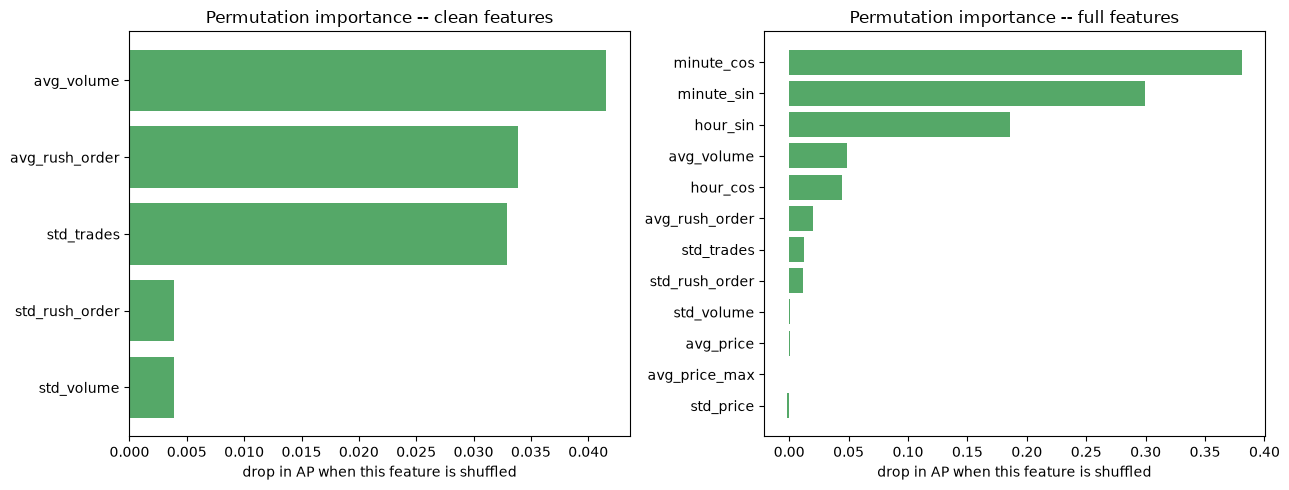

In [20]:
# Chart both feature sets' importances side by side, sorted largest-first.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, feature_set in zip(axes, ("clean", "full")):
    df = importance_frames[feature_set]
    ax.barh(df["feature"][::-1], df["importance_mean"][::-1], color=PALETTE["accent"])
    ax.set_xlabel("drop in AP when this feature is shuffled")
    ax.set_title(f"Permutation importance -- {feature_set} features")
plt.tight_layout()
plt.show()


**Takeaway -- this revised our original hypothesis.** We had suspected
price-level columns (`avg_price`, `std_price`, `avg_price_max`) were driving
the full-feature inflation, acting as a hidden coin-identity fingerprint.
The data does not support that: permuting those columns changes AP by only
-0.002 to +0.001, effectively zero. Instead, the dominant features by a wide
margin are the **time-of-day** encodings (`minute_cos`, `minute_sin`,
`hour_sin`) -- together far larger than every volume/trade feature combined.
Two explanations remain open and this notebook cannot distinguish them: (a)
pump organizers genuinely favor certain times of day, a real signal; or (b)
with only 317 events, a small number of recurring hour/minute values let the
model partially memorize "this time slot correlates with training-era
pumps" in a way that still partly transfers forward.


## 12. Full comparison: every model, every horizon

Honest split, tuned hyperparameters, full feature set -- how does each
model's AP change as the early-warning horizon lengthens?


In [21]:
honest = records[records.protocol == "honest_P2"]
prevalence_by_h = honest[honest.feature_set == "clean"].groupby("horizon_min")["prevalence"].first()

for feature_set in ("clean", "full"):
    print(f"=== {feature_set} feature set, honest split, AP by model x horizon ===")
    pivot = honest[honest.feature_set == feature_set].pivot(index="model", columns="horizon_min", values="ap")
    display(pivot.round(3))
    print()

print("=== base rate (prevalence) per horizon ===")
display(prevalence_by_h.round(4))


=== clean feature set, honest split, AP by model x horizon ===


horizon_min,1,3,5,10,30,60
model,,,,,,
decision_tree,0.091,0.064,0.074,0.102,0.197,0.315
knn,0.112,0.066,0.064,0.099,0.181,0.298
lightgbm,0.143,0.083,0.082,0.102,0.202,0.310
linear_svm,0.099,0.076,0.078,0.107,0.202,0.314
logreg,0.107,0.077,0.079,0.108,0.202,0.314
random_forest,0.142,0.094,0.096,0.121,0.217,0.326



=== full feature set, honest split, AP by model x horizon ===


horizon_min,1,3,5,10,30,60
model,,,,,,
decision_tree,0.150,0.351,0.475,0.470,0.510,0.530
knn,0.200,0.238,0.349,0.413,0.459,0.490
lightgbm,0.344,0.462,0.507,0.544,0.563,0.557
linear_svm,0.187,0.215,0.263,0.398,0.531,0.540
logreg,0.188,0.207,0.253,0.391,0.531,0.540
random_forest,0.356,0.524,0.567,0.574,0.547,0.544



=== base rate (prevalence) per horizon ===


horizon_min
1     0.0063
3     0.0191
5     0.0309
10    0.0571
30    0.1463
60    0.2616
Name: prevalence, dtype: float64

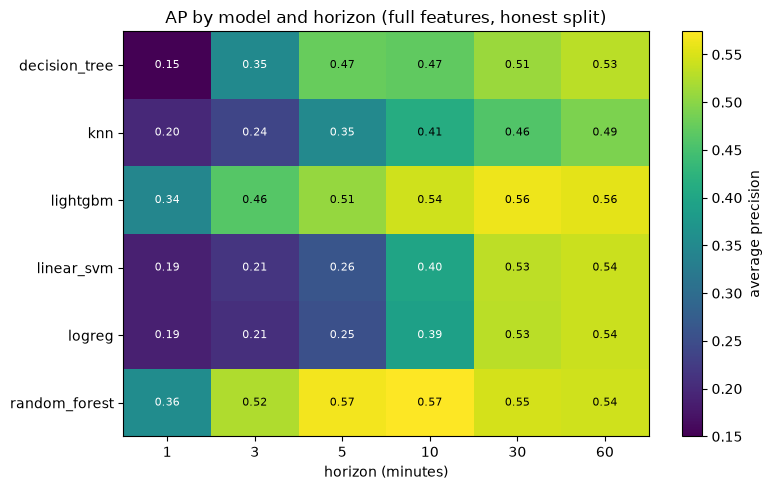

Best model per horizon, as a multiple of base rate:
  h= 1: random_forest   AP=0.356  (base rate 0.006, lift=56.6x)
  h= 3: random_forest   AP=0.524  (base rate 0.019, lift=27.4x)
  h= 5: random_forest   AP=0.567  (base rate 0.031, lift=18.3x)
  h=10: random_forest   AP=0.574  (base rate 0.057, lift=10.1x)
  h=30: lightgbm        AP=0.563  (base rate 0.146, lift=3.8x)
  h=60: lightgbm        AP=0.557  (base rate 0.262, lift=2.1x)


In [22]:
# A heatmap makes "which model wins at which horizon" easy to scan.
full_pivot = honest[honest.feature_set == "full"].pivot(index="model", columns="horizon_min", values="ap")
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(full_pivot.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(full_pivot.columns)))
ax.set_xticklabels(full_pivot.columns)
ax.set_yticks(range(len(full_pivot.index)))
ax.set_yticklabels(full_pivot.index)
for i in range(full_pivot.shape[0]):
    for j in range(full_pivot.shape[1]):
        ax.text(j, i, f"{full_pivot.values[i, j]:.2f}", ha="center", va="center",
                color="white" if full_pivot.values[i, j] < full_pivot.values.max() * 0.7 else "black", fontsize=8)
ax.set_xlabel("horizon (minutes)")
ax.set_title("AP by model and horizon (full features, honest split)")
fig.colorbar(im, ax=ax, label="average precision")
plt.tight_layout()
plt.show()

best_model = full_pivot.idxmax()
print("Best model per horizon, as a multiple of base rate:")
for h in full_pivot.columns:
    ap = full_pivot.loc[best_model[h], h]
    print(f"  h={h:>2}: {best_model[h]:14s}  AP={ap:.3f}  (base rate {prevalence_by_h[h]:.3f}, lift={ap / prevalence_by_h[h]:.1f}x)")


**Takeaway:** Random Forest and LightGBM are consistently the top two
models at every horizon -- Random Forest leads at short horizons (1-10
min), LightGBM edges ahead at longer ones (30-60 min). As a multiple of the
base rate, the best model's lift ranges from about 57x at h=1 down to 2.1x
at h=60: early warning is relatively much stronger than near-onset
detection in rank terms, even though absolute AP is lower at short horizons
(simply because the base rate itself is far smaller there).


## 13. How expensive is each model to train and run?

Accuracy is not the only thing that matters in a deployed system -- a model
that is only marginally better but 100x slower to retrain may not be worth
it. The chart below uses the real fit/inference times recorded during
evaluation (full feature set, honest split, h=10).


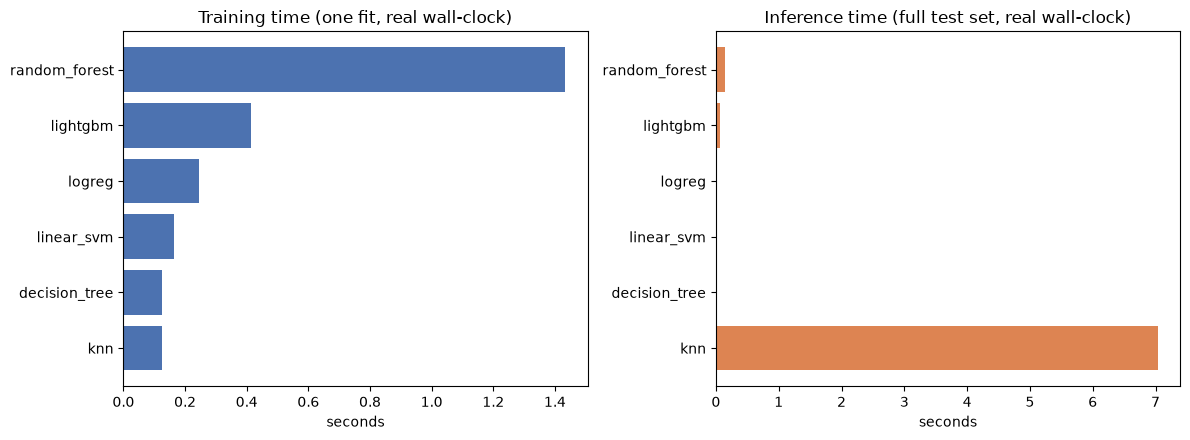

,fit_time_sec,inference_time_sec
model,,
knn,0.1249,7.0374
decision_tree,0.1265,0.0028
linear_svm,0.1645,0.0083
logreg,0.2443,0.0077
lightgbm,0.4144,0.0691
random_forest,1.4339,0.1462


In [23]:
cost = records[(records.horizon_min == 10) & (records.protocol == "honest_P2") & (records.feature_set == "full")] \
    .set_index("model")[["fit_time_sec", "inference_time_sec"]].sort_values("fit_time_sec")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].barh(cost.index, cost["fit_time_sec"], color=PALETTE["honest"])
axes[0].set_xlabel("seconds")
axes[0].set_title("Training time (one fit, real wall-clock)")
axes[1].barh(cost.index, cost["inference_time_sec"], color=PALETTE["random"])
axes[1].set_xlabel("seconds")
axes[1].set_title("Inference time (full test set, real wall-clock)")
plt.tight_layout()
plt.show()

cost.round(4)


**Takeaway:** Random Forest and LightGBM -- the two most accurate models --
are also comparatively cheap to train and to score at this data size, so
there is no real accuracy/cost trade-off being made by preferring them here.
KNN's inference time stands out as the slowest, which is expected: it has
to compare against the whole training set at prediction time.


## 14. Checking live deployment feasibility

All of the above is measured on 2018-2021 historical data. Before assuming
this model could score live coins today, we checked Binance's real, live
market directly.


In [24]:
with open(PROJECT_ROOT / "results" / "live_binance_universe_check.json") as f:
    live_check = json.load(f)

print(f"checked at: {live_check['checked_at_utc']}")
print(f"live BTC-quoted spot pairs (actively trading): {live_check['btc_quoted_pairs']}")
print(f"live USDT-quoted spot pairs (actively trading): {live_check['usdt_quoted_pairs']}")
print(f"live distinct base assets, any quote: {live_check['distinct_base_assets_any_quote']}")
print()
print(f"training data's BTC-paired coins: {summary['n_symbols']}")
print(f"-> the training universe ({summary['n_symbols']} coins) is "
      f"{summary['n_symbols'] / live_check['btc_quoted_pairs']:.1f}x larger than "
      f"today's live BTC-quoted universe ({live_check['btc_quoted_pairs']} coins)")


checked at: 2026-10-28T13:54:59.399557+00:00
live BTC-quoted spot pairs (actively trading): 38
live USDT-quoted spot pairs (actively trading): 519
live distinct base assets, any quote: 520

training data's BTC-paired coins: 85
-> the training universe (85 coins) is 2.2x larger than today's live BTC-quoted universe (38 coins)


**Takeaway:** the live BTC-quoted pair universe has shrunk to less than half
of what this model was trained on. That alone would limit real coverage,
and on top of that this model's features are 25-second resolution with an
undocumented original formula, while live Binance data is 1-minute
resolution with a different, known formula -- so this particular model has
no live deployment path. The platform's live scoring instead uses a
separate cross-sectional model trained directly on real Binance 1-minute
data (documented in the project's README, not in this notebook).


## 15. Limitations

- **Small event count.** With only 317 (or, after the strict pre-onset
  filter, effectively 96-220 held-out events per split) confirmed events,
  bootstrap confidence intervals are wide enough that even the largest
  observed inflation effects are not cleanly statistically significant.
- **Hyperparameter search is a small, per-parameter grid**, not an
  exhaustive search -- the numbers above describe a reasonable configuration
  for each model, not a claim of global optimality.
- **No probability calibration.** Every score in this notebook is a ranking
  score (or an uncalibrated class probability), not a calibrated
  probability -- it should not be read as "an X% chance of a pump."
- **The time-of-day signal is not fully explained.** Permutation importance
  shows it is the dominant driver of full-feature performance, but this
  notebook cannot distinguish genuine pump-timing behavior from a
  small-sample memorization artifact (Section 11).
- **This model cannot be deployed against live data.** Its features use an
  undocumented 25-second-resolution formula that does not match live
  1-minute Binance data (Section 14).
- This notebook evaluates one specific model family (per-event early
  warning on one coin at a time). A second, separately implemented model
  that ranks every live coin against every other coin at the same minute is
  documented and deployed elsewhere in this project, not inside this
  notebook.

## 16. Summary

- A naive random train/test split does **not** meaningfully distort results
  when only volume/order-flow/trade-count features are used, but it **does**
  meaningfully distort results once price-level and time-of-day features are
  added -- and the effect is largest for the most flexible models.
- That distortion is caused by the split protocol itself, not by how much
  training data each side gets (Section 10).
- The single biggest driver of the full-feature model's apparent skill is
  time-of-day encoding, not price level as initially suspected (Section 11)
  -- a genuinely surprising result that changed the direction of this
  analysis.
- Random Forest and LightGBM are consistently the strongest, and among the
  cheaper models to run, across every horizon tested (Sections 12-13).
- This model, as trained, has no path to live deployment; a separate,
  live-compatible model handles that role in the deployed platform.
